hi my name is mstafa
subscribe my channel and
ask me your question
Github.com/mstafafarahani
Mstafa.farahani@gmail.com
You tube: @GEEmap
Channel telegram : @GEEmap
Whatsapp +989381272118
learning satelite imagery remote sensing
I install and import packages

In [1]:
%pip install pygis -q
import ee, geemap, pandas as pd, matplotlib.pyplot as plt

I Register and Authenticate in Google Earth Engine
you need to create account in earth engine
to run code
for example my account is"ee-mstafafarahanit54f"
replace your account intead of mine


In [2]:
try:
    ee.Initialize(project='ee-mstafafarahanit54f')
except:
    ee.Authenticate()
    ee.Initialize(project='ee-mstafafarahanit54f')


/*YOu CAN USE city or provinceORstate or country boundary , in this code i use city boundary

city = ee.FeatureCollection("WM/geoLab/geoBoundaries/600/ADM2")

provinceORstate = ee.FeatureCollection("FAO/GAUL_SIMPLIFIED_500m/2015/level1").

country = ee.FeatureCollection("FAO/GAUL/2015/level0").filter(ee.Filter.eq('ADM0_NAME', 'Kenya'))

replace city or country or provine to eachother

##Let's Show the map
source code and article:https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1#bands

In [10]:
import geemap
Map = geemap.Map(center=[0, 0], zoom=2, basemap='HYBRID')
country = ee.FeatureCollection("FAO/GAUL/2015/level0").filter(ee.Filter.eq('ADM0_NAME', 'Germany'))
Map.centerObject(country, 6)
Map.addLayer(country, {}, "Country")

# Shortened Cropland collection processing and mapping
Cropland = ee.ImageCollection("MODIS/061/MCD12Q1").select('LC_Type1').filterBounds(country).filterDate('2000-01-01', '2025-01-01')


# Map and add the Cropland layers in a few concise lines
Cropland = Cropland.map(lambda img: img.clip(country).eq(12).selfMask().multiply(ee.Image.pixelArea().divide(1e6)).set({'system:time_start': img.get('system:time_start')}))
Map.addLayer(Cropland.sum(), {'min': 32, 'max': 511, 'palette': ['#ff6d4c']}, 'Cropland Area Growth')
Map.add_legend(title="Cropland Area Growth", legend_dict={'Cropland Growth': '#ff6d4c'})
Map

Map(center=[51.05286656613133, 10.372108688819381], controls=(WidgetControl(options=['position', 'transparent_…

In [11]:
print('Image count:', Cropland.size().getInfo())

Image count: 24


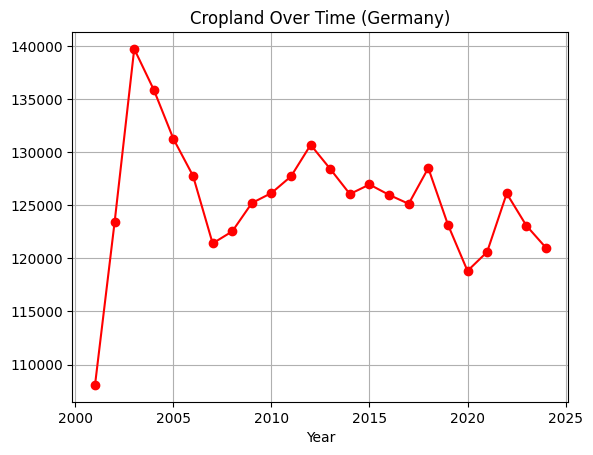

In [13]:
import pandas as pd, matplotlib.pyplot as plt
# Fetch, clean, and plot in 4 lines
data = Cropland.map(lambda i: ee.Feature(None, {'y': ee.Date(i.get('system:time_start')).format('YYYY'), 'a': i.reduceRegion(ee.Reducer.sum(), country.geometry(), 500, maxPixels=1e13).get('LC_Type1')})).reduceColumns(ee.Reducer.toList(2), ['y', 'a']).get('list').getInfo()
pd.DataFrame(data, columns=['Year', 'Area']).dropna().astype({'Year': int}).plot(x='Year', y='Area', marker='o', color='Red', legend=False, grid=True, title='Cropland Over Time (Germany)')
plt.show()

you're asking for truly direct download to your computer's Downloads folder csv file

In [14]:
import pandas as pd
from google.colab import files

# Reuse the data variable computed in the previous cell
pd.DataFrame(data, columns=['year', 'Cropland']).dropna().to_csv('Cropland.csv', index=False)
files.download('Cropland.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>